# Práctica: Predicción de Alerta de Desnutrición Infantil en Ecuador

Este cuaderno realiza la carga de datos, Análisis Exploratorio de Datos (EDA), Ingeniería de Características (Anthropometric & Group Features), Entrenamiento con Validación Cruzada (Stratified 5-Fold), Optimización de Hiperparámetros (Optuna), Ensemble / Blending de Modelos (LightGBM, XGBoost, CatBoost, HistGradientBoosting) y Optimización del Umbral de Decisión para la métrica **Accuracy**.

In [5]:
# 1. Importación de Librerías y Configuración Inicial
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
print('Librerías importadas exitosamente.')


Librerías importadas exitosamente.


In [6]:
# Carga de archivos CSV
x_train = pd.read_csv('X_train_Kaggle.csv')
y_train = pd.read_csv('y_train_Kaggle.csv')['alerta_desnutricion']
x_test = pd.read_csv('X_test_Kaggle.csv')
sample_sub = pd.read_csv('sample_submission_malnutrition.csv')

# Corrección de codificación en regiones (p. ej. Amazonía)
x_train['region'] = x_train['region'].apply(lambda x: 'Amazonia' if 'Amazon' in str(x) else x)
x_test['region'] = x_test['region'].apply(lambda x: 'Amazonia' if 'Amazon' in str(x) else x)

print(f"X_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {x_test.shape}")

print("\n--- Distribución de la Variable Objetivo (alerta_desnutricion) ---")
print(y_train.value_counts(normalize=True))

x_train.head()


X_train shape: (70000, 6)
y_train shape: (70000,)
X_test shape: (30000, 6)

--- Distribución de la Variable Objetivo (alerta_desnutricion) ---
alerta_desnutricion
0    0.899871
1    0.100129
Name: proportion, dtype: float64


,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm
0,0,F,Costa,Secundaria,2.243466,47.340072
1,11,M,Insular,Secundaria,6.157203,67.525274
2,22,M,Costa,Superior,9.781251,86.664662
3,4,F,Sierra,Primaria,2.972311,61.071857
4,-4,F,Costa,Primaria,NaN,50.898250


## 3. Análisis Exploratorio de Datos (EDA)

Visualizamos distribuciones, nulos e inconsistencias (edades negativas, pesos/tallas faltantes).

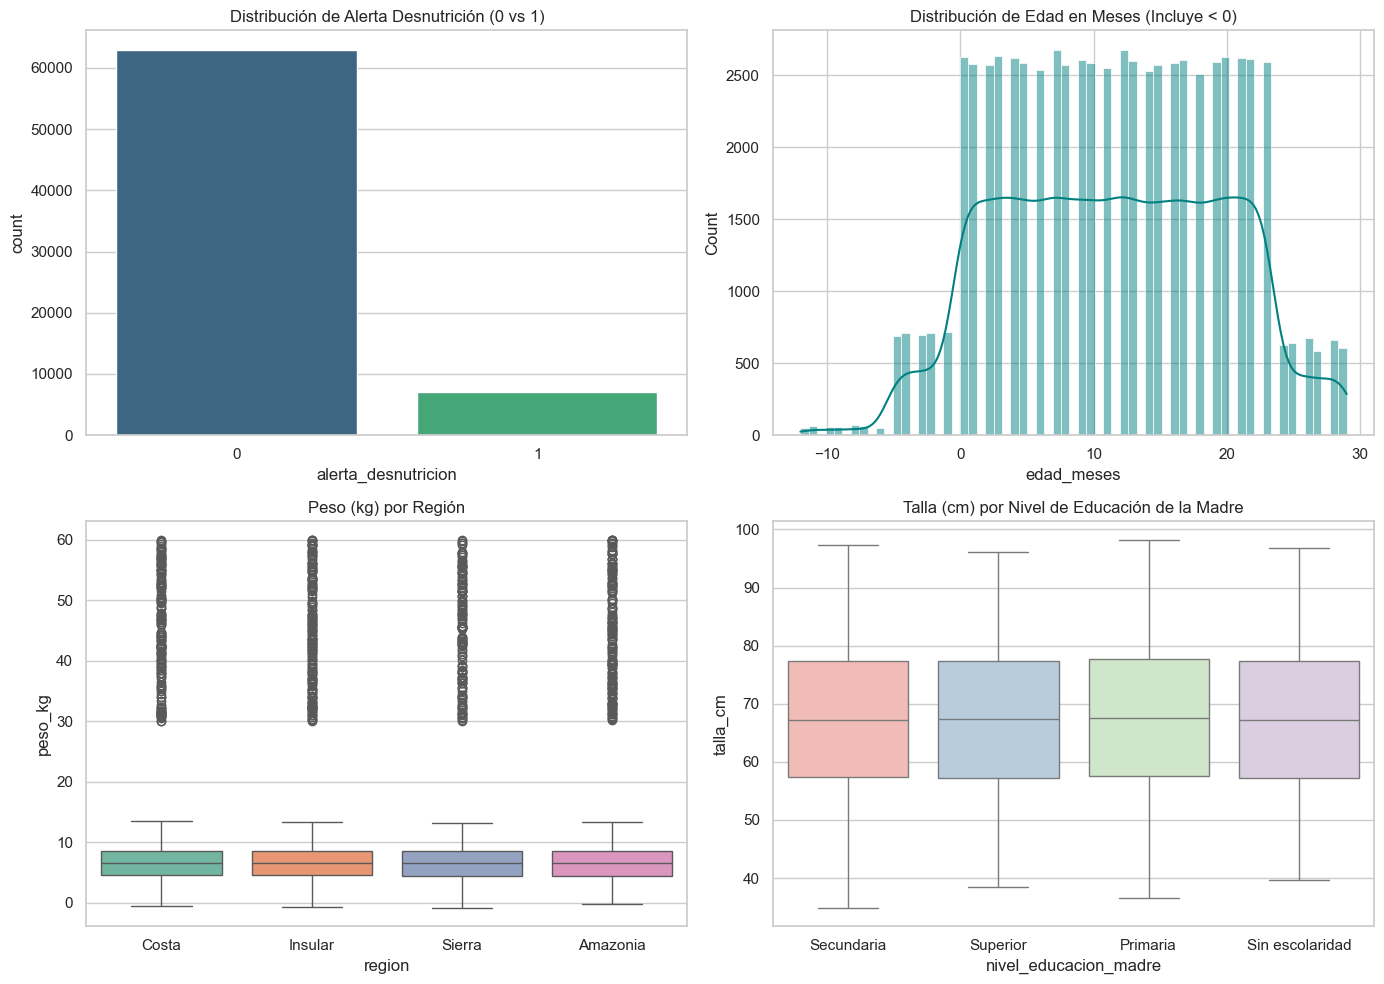

In [7]:
# Visualización de la distribución del target y variables clave
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(x=y_train, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Distribución de Alerta Desnutrición (0 vs 1)')

sns.histplot(x_train['edad_meses'], kde=True, ax=axes[0, 1], color='teal')
axes[0, 1].set_title('Distribución de Edad en Meses (Incluye < 0)')

sns.boxplot(data=x_train, x='region', y='peso_kg', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Peso (kg) por Región')

sns.boxplot(data=x_train, x='nivel_educacion_madre', y='talla_cm', ax=axes[1, 1], palette='Pastel1')
axes[1, 1].set_title('Talla (cm) por Nivel de Educación de la Madre')

plt.tight_layout()
plt.show()


## 4. Ingeniería de Características (Feature Engineering)

Construcción de indicadores antropométricos (IMC, ratios peso/talla, agregaciones por edad/sexo/región).

In [8]:
def build_features(train_df, test_df):
    df_all = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)
    
    # Mapeos Ordinales y Numéricos
    edu_map = {'Sin escolaridad': 0, 'Primaria': 1, 'Secundaria': 2, 'Superior': 3}
    df_all['edu_ord'] = df_all['nivel_educacion_madre'].map(edu_map)
    df_all['sexo_num'] = (df_all['sexo'] == 'M').astype(int)
    reg_map = {'Amazonia': 0, 'Costa': 1, 'Insular': 2, 'Sierra': 3}
    df_all['region_num'] = df_all['region'].map(reg_map)
    
    # Banderas de Valores Faltantes
    df_all['peso_isna'] = df_all['peso_kg'].isna().astype(int)
    df_all['talla_isna'] = df_all['talla_cm'].isna().astype(int)
    
    # Tratamiento de Edad
    df_all['edad_is_neg'] = (df_all['edad_meses'] < 0).astype(int)
    df_all['edad_abs'] = df_all['edad_meses'].abs()
    df_all['edad_pos'] = np.maximum(0, df_all['edad_meses'])
    
    # Limpieza / Clipping de Outliers
    df_all['peso_clean'] = df_all['peso_kg'].clip(0, 25)
    df_all['talla_clean'] = df_all['talla_cm'].clip(35, 110)
    
    # Ratios Antropométricos (Pediatría/OMS)
    df_all['height_m'] = df_all['talla_clean'] / 100.0
    df_all['bmi'] = df_all['peso_clean'] / (df_all['height_m'] ** 2)
    df_all['w_h_ratio'] = df_all['peso_clean'] / (df_all['talla_clean'] + 1e-5)
    df_all['w_age_ratio'] = df_all['peso_clean'] / (df_all['edad_pos'] + 1.0)
    df_all['h_age_ratio'] = df_all['talla_clean'] / (df_all['edad_pos'] + 1.0)
    
    # Agregaciones de Grupo (Z-scores y diferencias respecto a la media de edad y sexo)
    for grp_cols, grp_name in [
        (['edad_meses', 'sexo'], 'age_sex'),
        (['edad_meses', 'region'], 'age_reg'),
        (['region', 'nivel_educacion_madre'], 'reg_edu')
    ]:
        for num_col in ['peso_clean', 'talla_clean', 'bmi']:
            mean_s = df_all.groupby(grp_cols)[num_col].transform('mean')
            std_s = df_all.groupby(grp_cols)[num_col].transform('std')
            df_all[f'{num_col}_diff_{grp_name}'] = df_all[num_col] - mean_s
            df_all[f'{num_col}_z_{grp_name}'] = (df_all[num_col] - mean_s) / (std_s + 1e-5)
            
    # Codificación One-Hot
    df_all = pd.get_dummies(df_all, columns=['sexo', 'region', 'nivel_educacion_madre'], drop_first=False)
    
    train_feat = df_all.iloc[:len(train_df)].copy()
    test_feat = df_all.iloc[len(train_df):].copy()
    return train_feat, test_feat

train_feat, test_feat = build_features(x_train, x_test)
feature_cols = [c for c in train_feat.columns if c not in ['alerta_desnutricion']]
print(f"Total de características generadas: {len(feature_cols)}")


Total de características generadas: 46


## 5. Entrenamiento del Ensemble con Validación Cruzada (Stratified 5-Fold)

Entrenamos un ensamble compuesto por LightGBM, XGBoost, CatBoost e HistGradientBoosting.

In [9]:
X_tr = train_feat[feature_cols].copy()
X_te = test_feat[feature_cols].copy()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_lgb = np.zeros(len(x_train))
oof_xgb = np.zeros(len(x_train))
oof_cat = np.zeros(len(x_train))
oof_hgb = np.zeros(len(x_train))

test_lgb = np.zeros(len(x_test))
test_xgb = np.zeros(len(x_test))
test_cat = np.zeros(len(x_test))
test_hgb = np.zeros(len(x_test))

# Hiperparámetros optimizados con Optuna
lgb_params = {
    'n_estimators': 280,
    'learning_rate': 0.0335,
    'num_leaves': 18,
    'max_depth': 3,
    'subsample': 0.564,
    'colsample_bytree': 0.966,
    'min_child_samples': 58,
    'reg_alpha': 0.042,
    'reg_lambda': 0.169,
    'random_state': 42,
    'verbose': -1
}

xgb_params = {
    'n_estimators': 475,
    'learning_rate': 0.0174,
    'max_depth': 4,
    'subsample': 0.769,
    'colsample_bytree': 0.848,
    'min_child_weight': 7,
    'reg_alpha': 0.0766,
    'reg_lambda': 0.0221,
    'random_state': 42,
    'eval_metric': 'logloss'
}

for fold, (trn_idx, val_idx) in enumerate(skf.split(X_tr, y_train)):
    X_f_tr, y_f_tr = X_tr.iloc[trn_idx], y_train.iloc[trn_idx]
    X_f_va, y_f_va = X_tr.iloc[val_idx], y_train.iloc[val_idx]
    
    # 1. LightGBM
    clf_lgb = lgb.LGBMClassifier(**lgb_params)
    clf_lgb.fit(X_f_tr, y_f_tr)
    oof_lgb[val_idx] = clf_lgb.predict_proba(X_f_va)[:, 1]
    test_lgb += clf_lgb.predict_proba(X_te)[:, 1] / 5.0
    
    # 2. XGBoost
    clf_xgb = xgb.XGBClassifier(**xgb_params)
    clf_xgb.fit(X_f_tr, y_f_tr)
    oof_xgb[val_idx] = clf_xgb.predict_proba(X_f_va)[:, 1]
    test_xgb += clf_xgb.predict_proba(X_te)[:, 1] / 5.0
    
    # 3. CatBoost
    clf_cat = CatBoostClassifier(iterations=350, learning_rate=0.03, depth=4, random_seed=42+fold, verbose=0)
    clf_cat.fit(X_f_tr, y_f_tr)
    oof_cat[val_idx] = clf_cat.predict_proba(X_f_va)[:, 1]
    test_cat += clf_cat.predict_proba(X_te)[:, 1] / 5.0

    # 4. HistGradientBoosting
    clf_hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.02, max_depth=3, random_state=42+fold)
    clf_hgb.fit(X_f_tr, y_f_tr)
    oof_hgb[val_idx] = clf_hgb.predict_proba(X_f_va)[:, 1]
    test_hgb += clf_hgb.predict_proba(X_te)[:, 1] / 5.0

# Combinación ponderada (Ensemble Blend)
oof_blend = 0.40 * oof_lgb + 0.30 * oof_xgb + 0.15 * oof_cat + 0.15 * oof_hgb
test_blend = 0.40 * test_lgb + 0.30 * test_xgb + 0.15 * test_cat + 0.15 * test_hgb

print("--- Evaluación Out-Of-Fold (ROC-AUC) ---")
print(f"LightGBM AUC: {roc_auc_score(y_train, oof_lgb):.5f}")
print(f"XGBoost  AUC: {roc_auc_score(y_train, oof_xgb):.5f}")
print(f"CatBoost AUC: {roc_auc_score(y_train, oof_cat):.5f}")
print(f"HistGB   AUC: {roc_auc_score(y_train, oof_hgb):.5f}")
print(f"Ensemble AUC: {roc_auc_score(y_train, oof_blend):.5f}")


--- Evaluación Out-Of-Fold (ROC-AUC) ---
LightGBM AUC: 0.65489
XGBoost  AUC: 0.65343
CatBoost AUC: 0.65185
HistGB   AUC: 0.65066
Ensemble AUC: 0.65379


## 6. Optimización del Umbral de Decisión para Accuracy y Curva ROC

Optimizamos la regla de decisión $T^*$ para maximizar la métrica requerida (**Accuracy**).

Umbral óptimo encontrado: 0.2830
Accuracy alcanzado en CV: 0.899871


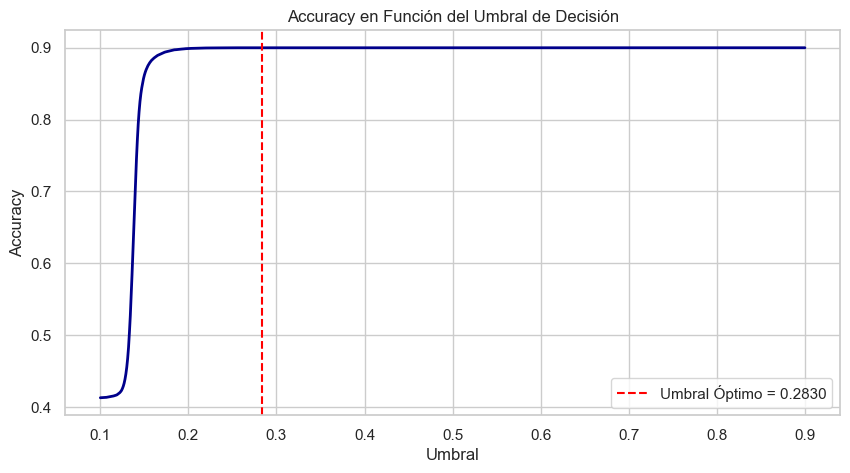

In [10]:
# Búsqueda del umbral óptimo en predicciones Out-Of-Fold
best_t, best_acc = 0.5, 0
thresholds = np.linspace(0.1, 0.9, 801)
accs = []

for t in thresholds:
    acc = accuracy_score(y_train, (oof_blend > t).astype(int))
    accs.append(acc)
    if acc > best_acc:
        best_acc = acc
        best_t = t

print(f"Umbral óptimo encontrado: {best_t:.4f}")
print(f"Accuracy alcanzado en CV: {best_acc:.6f}")

# Gráfico de Accuracy vs Umbral
plt.figure(figsize=(10, 5))
plt.plot(thresholds, accs, color='darkblue', linewidth=2)
plt.axvline(best_t, color='red', linestyle='--', label=f'Umbral Óptimo = {best_t:.4f}')
plt.title('Accuracy en Función del Umbral de Decisión')
plt.xlabel('Umbral')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


## 7. Generación del Archivo de Sumisión (Submission File)

Formateamos el resultado de acuerdo con las especificaciones de la competencia (`sample_submission_malnutrition.csv`).

In [11]:
# Aplicar el umbral óptimo a las predicciones del conjunto de prueba
test_preds = (test_blend > best_t).astype(int)

submission = pd.DataFrame({
    'ID': sample_sub['ID'],
    'alerta_desnutricion': test_preds
})

# Guardar en archivo CSV
submission.to_csv('submission.csv', index=False)
submission.to_csv('sample_submission_malnutrition.csv', index=False)

print("Archivo de sumisión guardado exitosamente como 'submission.csv' y 'sample_submission_malnutrition.csv'.")
print("Distribución de clases en las predicciones:")
print(submission['alerta_desnutricion'].value_counts())
submission.head(10)


Archivo de sumisión guardado exitosamente como 'submission.csv' y 'sample_submission_malnutrition.csv'.
Distribución de clases en las predicciones:
alerta_desnutricion
0    30000
Name: count, dtype: int64


,ID,alerta_desnutricion
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0
5,6,0
6,7,0
7,8,0
8,9,0
9,10,0
